<a href="https://colab.research.google.com/github/Marte-Jupiter/Modelagem-Computacional/blob/main/Deteccao_Pluma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#<center> Marcos Júnior Souza Gomes - 150096</center>

In [1]:
!pip install opencv-python matplotlib
!pip install 'git+https://github.com/facebookresearch/segment-anything.git'
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-rpil_ksi
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-rpil_ksi
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36634 sha256=28e44d3967bcdda63e4d2aa53fd13608c316368001b69b66907f7b17be2dd7b0
  Stored in directory: /tmp/pip-ephem-wheel-cache-phz25r4a/wheels/5d/7b/4a/c7fda89f2e27647dd0816f51ea103992b1b6f0f53ad234895c
Successfully built segment_anything


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from segment_anything import sam_model_registry, SamPredictor

sam_checkpoint = "sam_vit_h_4b8939.pth"
model_type = "vit_h"

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Usando o dispositivo: {device}")

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)
predictor = SamPredictor(sam)

def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)

def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0,0,0,0), lw=2))

Usando o dispositivo: cpu


In [9]:
import os
import cv2
import numpy as np

image_path = "pluma_suzano.jpg"
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
predictor.set_image(image)

# Prompt 1: Caixa delimitadora ampla cobrindo a pluma central principal
box_1 = np.array([600, 1000, 2200, 1600])

# Prompt 2: Caixa delimitadora focada apenas na base mais densa da pluma (junto à estrutura)
box_2 = np.array([600, 1300, 1100, 1600])

# Prompt 3: Caixa delimitadora + Ponto Negativo (apontando para o céu azul no topo à direita para evitar confusão com o fundo)
box_3 = np.array([600, 1000, 2200, 1600])
point_coords = np.array([[2500, 500]]) # Coordenada no céu azul (X=2500, Y=500)
point_labels = np.array([0]) # 0 = background (negativo)

prompts = [
    {"box": box_1, "title": "Config 1: Bounding Box Ampla", "points": None, "labels": None},
    {"box": box_2, "title": "Config 2: Bounding Box na Base", "points": None, "labels": None},
    {"box": box_3, "title": "Config 3: Box Ampla + Ponto Negativo", "points": point_coords, "labels": point_labels}
]

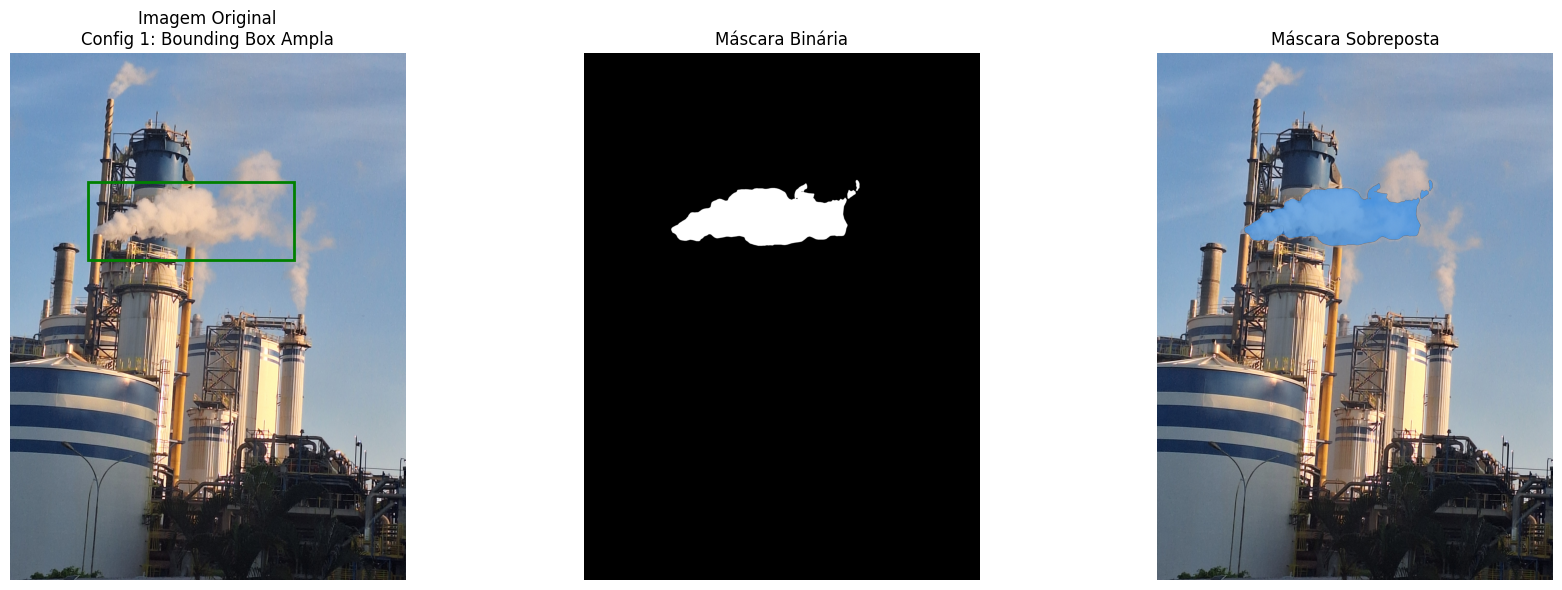

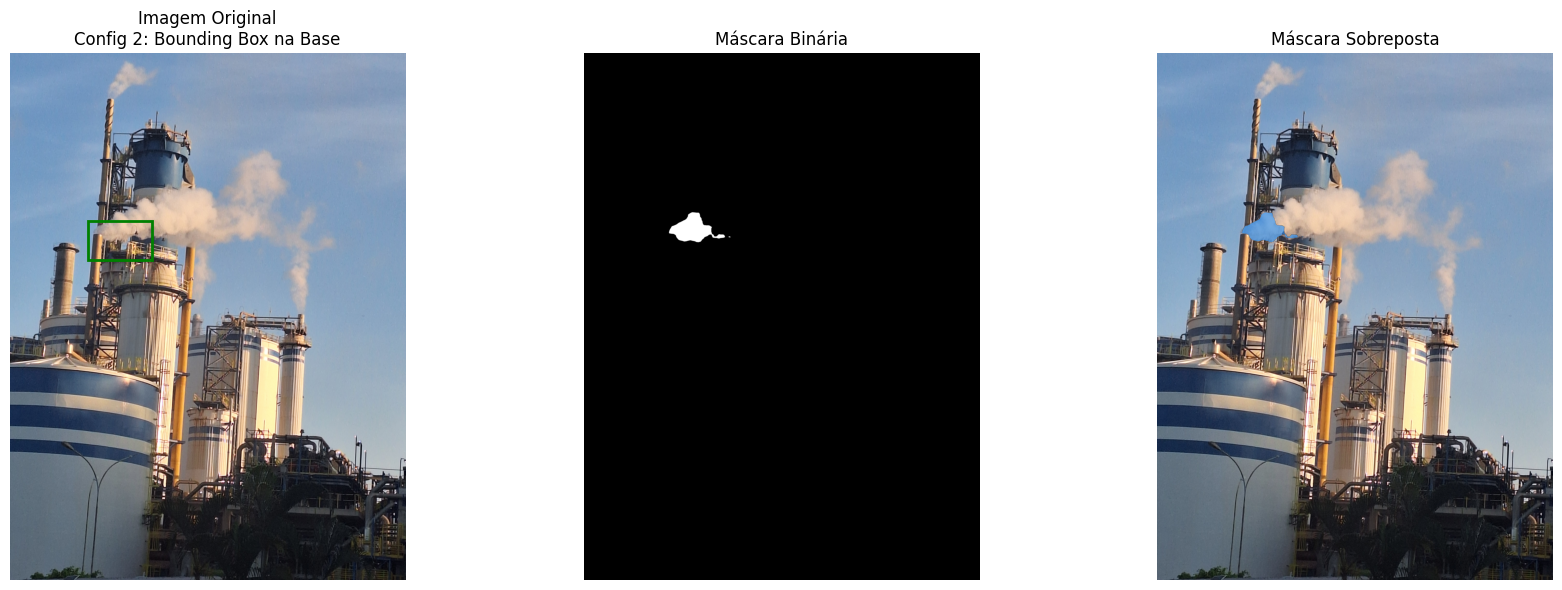

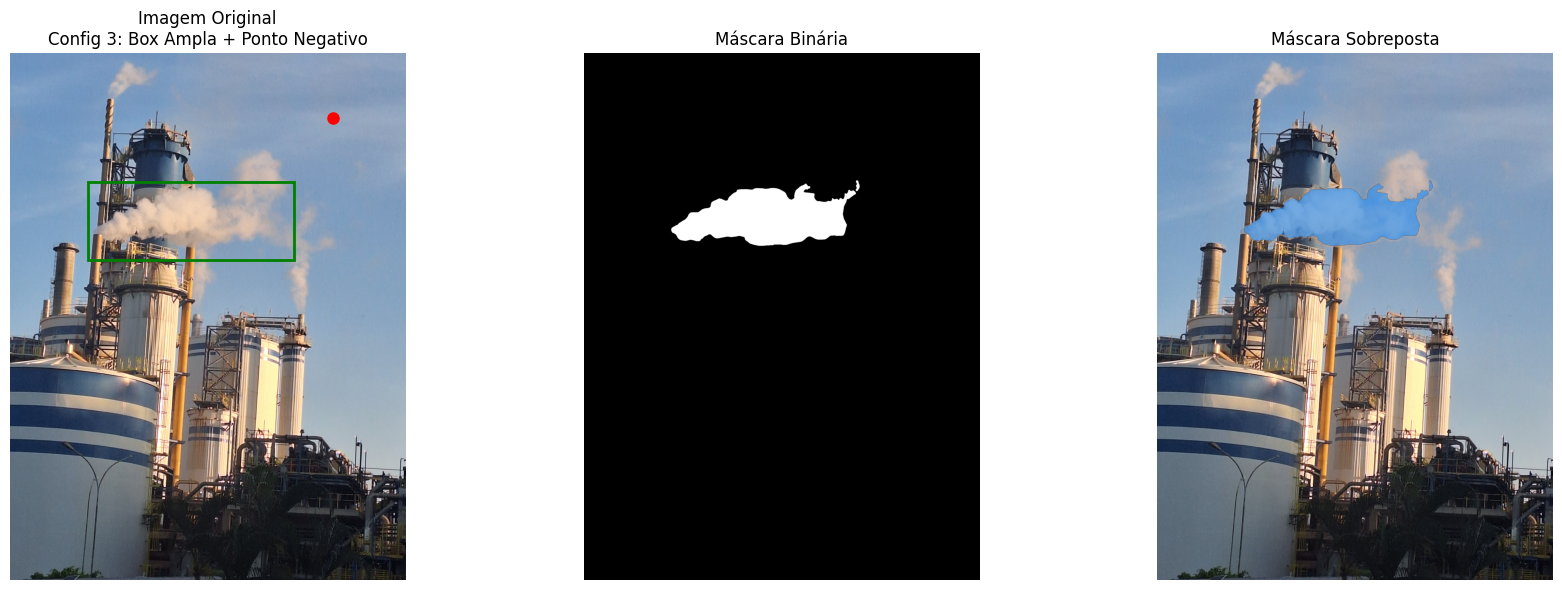

In [10]:
for prompt in prompts:
    if prompt["points"] is not None:
        masks, scores, logits = predictor.predict(
            box=prompt["box"],
            point_coords=prompt["points"],
            point_labels=prompt["labels"],
            multimask_output=False
        )
    else:
        masks, scores, logits = predictor.predict(
            box=prompt["box"],
            multimask_output=False
        )

    mask = masks[0]

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(image)
    show_box(prompt["box"], axes[0])
    if prompt["points"] is not None:
        axes[0].plot(prompt["points"][0][0], prompt["points"][0][1], 'ro', markersize=8) # Ponto vermelho
    axes[0].set_title(f'Imagem Original\n{prompt["title"]}')
    axes[0].axis('off')

    axes[1].imshow(mask, cmap='gray')
    axes[1].set_title('Máscara Binária')
    axes[1].axis('off')

    axes[2].imshow(image)
    show_mask(mask, axes[2])
    axes[2].set_title('Máscara Sobreposta')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

# Análise Crítica da Segmentação da Pluma Térmica (Modelo SAM)

Com base nos testes realizados utilizando o Segment Anything Model (SAM) com três configurações diferentes de prompts (Bounding Box Ampla, Bounding Box na Base e Box Ampla + Ponto Negativo), apresento a avaliação da segmentação automática da pluma emitida pelas chaminés da unidade de Jacareí.

### 1. Avaliação da Máscara (Cobertura, Excesso e Omissão)
**A máscara cobre a pluma? Inclui regiões que não pertencem a ela? Deixa partes da fumaça de fora?**

A máscara gerada pelo SAM consegue cobrir apenas o "núcleo" de maior densidade e opacidade da pluma. Nos resultados obtidos, observou-se que o modelo foi bem-sucedido em não incluir regiões indesejadas (como o céu azul de fundo ou as estruturas cilíndricas e metálicas da fábrica), evitando falsos positivos.

No entanto, o modelo deixa porções consideráveis da fumaça de fora. As extremidades mais translúcidas, finas e as áreas onde a pluma já se encontra em franco processo de dispersão horizontal não foram capturadas. Ao testarmos a *Configuração 2* (restringindo a caixa à base da chaminé), ficou evidente que o modelo se limita à área de atenção forçada e não compreende o conceito de continuidade da fumaça, segmentando apenas um fragmento muito restrito. Na *Configuração 3*, a adição de um ponto negativo no céu não alterou significativamente a máscara, pois o problema central não era a inclusão de falsos positivos, mas sim a sub-segmentação (omissão) da pluma dispersa.

### 2. Dificuldades de Segmentação
**Quais características da imagem dificultaram a segmentação?**

A maior barreira para a segmentação foi a natureza amorfa da fumaça e a completa ausência de bordas rígidas (*hard edges*).

A fumaça, por outro lado, possui limites em degradê espacial. A densidade do material particulado diminui suavemente à medida que se espalha, fazendo com que a fumaça se desvaneça no ar atmosférico. Ao deparar-se com esse limite difuso, o algoritmo tem extrema dificuldade em traçar uma linha divisória de onde termina a pluma e onde começa o céu, levando-o a cortar a segmentação prematuramente nas áreas mais consolidadas.

### 3. Impacto da Iluminação, Contraste e Semelhança
**Como a iluminação, o contraste e a semelhança entre fumaça e nuvens afetaram o resultado?**

Estes fatores atmosféricos afetaram o modelo das seguintes formas:
*   **Iluminação e Contraste:** A iluminação solar direta incidente sobre a fumaça criou uma zona central muito clara, brilhante e de alto contraste em relação ao resto da imagem. Isso fez com que o modelo priorizasse fortemente essa área como o "objeto principal", descartando as partes sombreadas ou menos densas ao redor. O baixo contraste entre as bordas translúcidas da fumaça e o céu claro também confundiu o algoritmo, mascarando a real extensão horizontal da pluma.
*   **Semelhança com Nuvens:** Em cenários onde a fumaça começa a se dispersar, sua textura, refletância e cor tornam-se quase idênticas à formação de nuvens ou à cor acinzentada/clara do próprio céu (especialmente em dias de inverno no Vale do Paraíba). Como o modelo tenta ativamente evitar englobar o fundo (céu/nuvens) junto com o objeto delimitado pela caixa, ele adota uma postura conservadora, interrompendo a segmentação antes de chegar nas áreas de transição suave.